In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle
from PIL import Image

In [2]:
img = np.array(Image.open("Nissan.jpg").convert("L"))
M, N = img.shape

F = np.fft.fftshift(np.fft.fft2(img))
spectrum = np.log(1 + np.abs(F))


u = np.arange(M)
v = np.arange(N)
V, U = np.meshgrid(v, u)
D = np.sqrt((U - M/2)**2 + (V - N/2)**2)

D0 = 50

Ideal High Pass Filter(IHF)

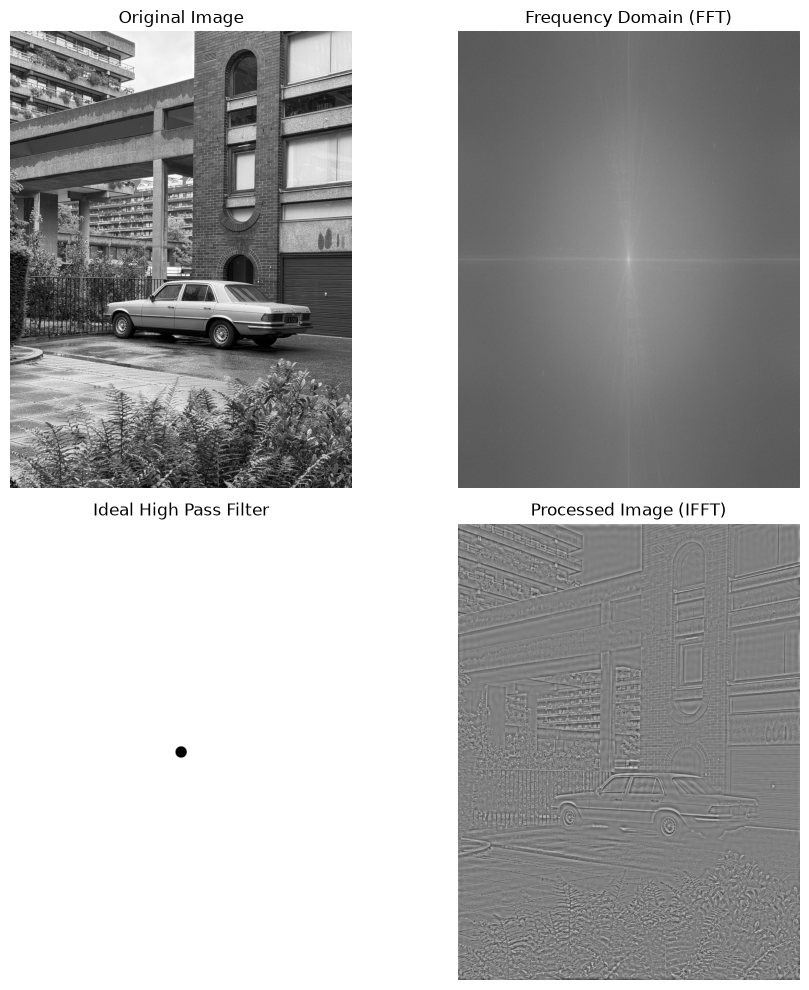

In [3]:

H_ideal = np.zeros((M, N))
H_ideal[D > D0] = 1
G_ideal = H_ideal * F
processed_ideal = np.real(np.fft.ifft2(np.fft.ifftshift(G_ideal)))

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs[0, 0].imshow(img, cmap='gray')
axs[0, 0].set_title("Original Image")
axs[0, 0].axis('off')
axs[0, 1].imshow(spectrum, cmap='gray')
axs[0, 1].set_title("Frequency Domain (FFT)")
axs[0, 1].axis('off')
axs[1, 0].imshow(H_ideal, cmap='gray')
axs[1, 0].set_title("Ideal High Pass Filter")
axs[1, 0].axis('off')
axs[1, 1].imshow(processed_ideal, cmap='gray')
axs[1, 1].set_title("Processed Image (IFFT)")
axs[1, 1].axis('off')
plt.tight_layout()
plt.show()

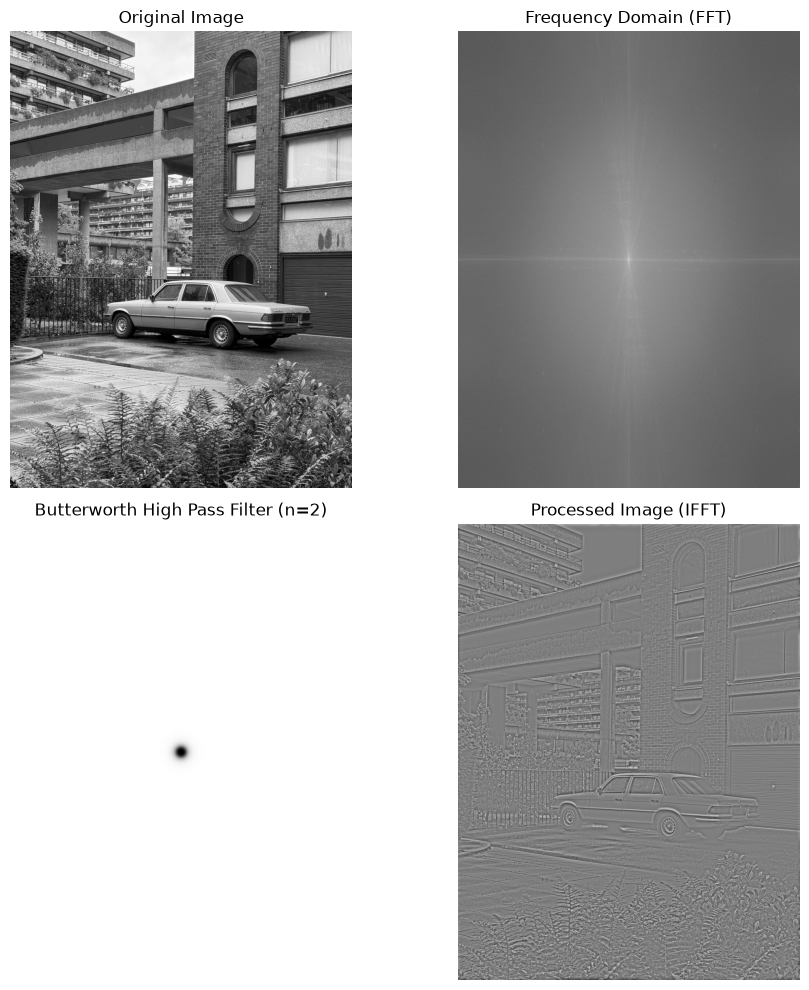

In [4]:
n = 2  # Filter order
D_safe = np.maximum(D, 1e-10)  # Prevent division by zero at the center
H_butterworth_hp = 1 / (1 + (D0 / D_safe)**(2 * n))
G_butterworth_hp = H_butterworth_hp * F
processed_butterworth_hp = np.real(np.fft.ifft2(np.fft.ifftshift(G_butterworth_hp)))

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs[0, 0].imshow(img, cmap='gray')
axs[0, 0].set_title("Original Image")
axs[0, 0].axis('off')

axs[0, 1].imshow(spectrum, cmap='gray')
axs[0, 1].set_title("Frequency Domain (FFT)")
axs[0, 1].axis('off')

axs[1, 0].imshow(H_butterworth_hp, cmap='gray')
axs[1, 0].set_title(f"Butterworth High Pass Filter (n={n})")
axs[1, 0].axis('off')

axs[1, 1].imshow(processed_butterworth_hp, cmap='gray')
axs[1, 1].set_title("Processed Image (IFFT)")
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()